# led_clock — схемы

Источник всех картинок проекта. Каждая ячейка рисует одну схему, сохраняет её в `docs/diagrams/<имя>.svg` и показывает здесь же. В документации картинки вставляются как `![...](diagrams/<имя>.svg)`.

- Открыть и править: `./tools/diagrams.ps1 lab` → http://127.0.0.1:8888
- Пересобрать все SVG без браузера: `./tools/diagrams.ps1 render`

Подробно — [docs/diagrams.md](../../../../docs/diagrams.md) в корне монорепы.

In [1]:
import math
from pathlib import Path

from IPython.display import SVG, display
import schemdraw
import schemdraw.elements as elm
from schemdraw.segments import Segment, SegmentPoly, SegmentCircle, SegmentText

schemdraw.use('svg')
schemdraw.config(bgcolor='white', fontsize=12, font='Arial', margin=0.4)

OUT = Path('.')  # ноутбук выполняется из docs/diagrams/


def save(d, name):
    """Сохранить схему в docs/diagrams/<name>.svg и показать в ноутбуке."""
    path = OUT / f'{name}.svg'
    d.save(str(path))
    display(SVG(filename=str(path)))


# Цвета
ORANGE, ORANGE_EDGE = '#f28c28', '#a85a12'  # UA3 — оранжевый
FACE = '#d0d0d0'                            # код 8 — серая лицевая панель
PIN_COLOR = '#b07d2b'
PLUS = '#c00000'

# Индикатор E20362-I (docs/components/E20362-I-UA3.md)
SEGMENTS = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'DP']
SEG_PINS = {'A': 3, 'B': 9, 'C': 8, 'D': 6, 'E': 7, 'F': 4, 'G': 1, 'DP': 2}
PIN_FUNC = {1: 'G', 2: 'DP', 3: 'A', 4: 'F', 5: 'DIG2 +',
            6: 'D', 7: 'E', 8: 'C', 9: 'B', 10: 'DIG1 +'}

## E20362 — вид спереди и номера выводов

Размеры по даташиту TOYO: корпус 15 × 14 мм, цифра 9,2 мм, наклон 5°, шаг выводов 2,54 мм. Нижний ряд — выводы 1…5 слева направо, верхний — 10…6.

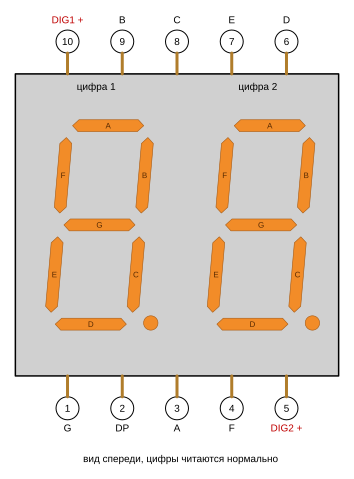

In [2]:
K = 0.6                      # 1 мм корпуса = 0.6 единицы рисунка
W, H = 15.0 * K, 14.0 * K
TILT = math.tan(math.radians(5))


def digit_segments(x0, y0, w, h, t):
    """Полигоны семи сегментов цифры; (x0, y0) — левый нижний угол."""
    hh = h / 2

    def hseg(y):
        return [(x0 + t, y), (x0 + t * 1.5, y + t / 2), (x0 + w - t * 1.5, y + t / 2),
                (x0 + w - t, y), (x0 + w - t * 1.5, y - t / 2), (x0 + t * 1.5, y - t / 2)]

    def vseg(x, ya, yb):
        return [(x, ya + t), (x + t / 2, ya + t * 1.5), (x + t / 2, yb - t * 1.5),
                (x, yb - t), (x - t / 2, yb - t * 1.5), (x - t / 2, ya + t * 1.5)]

    xl, xr = x0 + t / 2 + 0.02, x0 + w - t / 2 - 0.02
    segs = {'A': hseg(y0 + h), 'G': hseg(y0 + hh), 'D': hseg(y0),
            'F': vseg(xl, y0 + hh, y0 + h), 'B': vseg(xr, y0 + hh, y0 + h),
            'E': vseg(xl, y0, y0 + hh), 'C': vseg(xr, y0, y0 + hh)}
    # наклон вправо на 5° относительно низа цифры
    return {k: [(px + (py - y0) * TILT, py) for px, py in v] for k, v in segs.items()}


class E20362Front(elm.Element):
    def __init__(self, show_func=True, fs=1, **kwargs):
        """show_func=False — без подписей назначения выводов; fs — масштаб текста (для монтажной схемы)."""
        super().__init__(**kwargs)
        s = self.segments
        s.append(SegmentPoly([(0, 0), (W, 0), (W, H), (0, H)], fill=FACE, color='black', lw=1.5))

        dh, dw, t = 9.2 * K, 4.4 * K, 0.55 * K
        y0 = (H - dh) / 2
        for i, cx in enumerate((W / 2 - 3.75 * K, W / 2 + 3.75 * K)):   # цифры через 7,5 мм
            x0 = cx - dw / 2 - 0.15
            for name, poly in digit_segments(x0, y0, dw, dh, t).items():
                s.append(SegmentPoly(poly, fill=ORANGE, color=ORANGE_EDGE, lw=0.6))
                px = sum(p[0] for p in poly) / len(poly)
                py = sum(p[1] for p in poly) / len(poly)
                s.append(SegmentText((px, py), name, fontsize=8 * min(fs, 1.5), color='#5a2a00',
                                     align=('center', 'center'), zorder=5))
            s.append(SegmentCircle((x0 + dw + 0.35, y0 + t * 0.1), 0.2,
                                   fill=ORANGE, color=ORANGE_EDGE, lw=0.6))
            s.append(SegmentText((cx, H - 0.35), f'цифра {i + 1}', fontsize=10 * fs,
                                 align=('center', 'center')))

        # выводы: снизу 1..5 слева направо, сверху 10..6 слева направо
        r = 0.32 * max(1.0, 0.8 * fs)
        for i in range(5):
            x = W / 2 + (i - 2) * 2.54 * K
            for pin, y, va, ty in ((i + 1, -0.9, 'top', -1.35), (10 - i, H + 0.9, 'bottom', H + 1.35)):
                edge = 0 if y < 0 else H
                s.append(Segment([(x, edge), (x, y + (r if y < 0 else -r))], color=PIN_COLOR, lw=3))
                s.append(SegmentCircle((x, y), r, fill='white', color='black', lw=1))
                s.append(SegmentText((x, y), str(pin), fontsize=10 * fs, align=('center', 'center')))
                func = PIN_FUNC[pin]
                if show_func:
                    s.append(SegmentText((x, ty), func, fontsize=10 * fs,
                                         color=PLUS if '+' in func else 'black', align=('center', va)))


with schemdraw.Drawing(show=False) as d:
    d += E20362Front()
    d += elm.Label().at((W / 2, -2.4)).label('вид спереди, цифры читаются нормально', fontsize=10)
save(d, 'E20362-front')

## E20362 — внутренняя схема (CODE I, общий анод)

Как в даташите: у каждой цифры 8 светодиодов с общим анодом (10 / 5), катоды одноимённых сегментов обеих цифр соединены и выведены на один вывод.

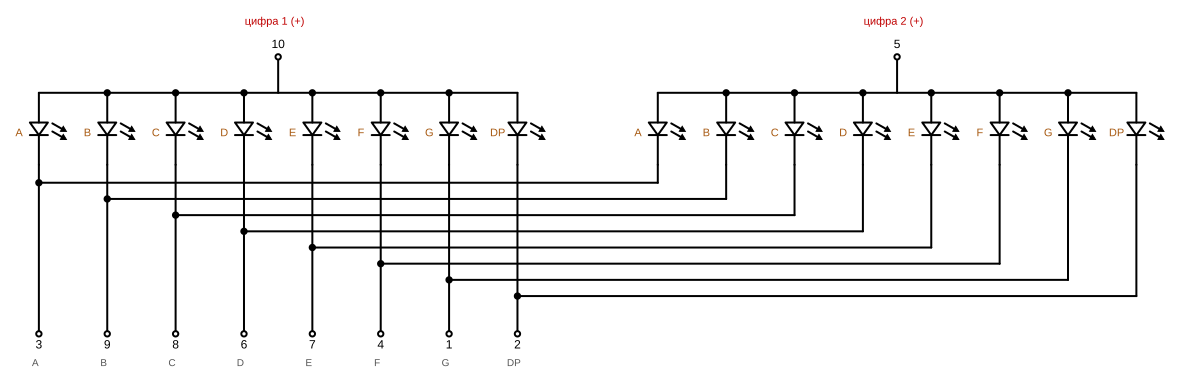

In [3]:
STEP, GAP, ROW = 1.9, 2.0, 0.45   # шаг светодиодов, зазор между цифрами, шаг перемычек

with schemdraw.Drawing(show=False) as d:
    d.config(unit=2)
    cathodes = {}
    for digit, (pin, xoff) in enumerate(((10, 0.0), (5, len(SEGMENTS) * STEP + GAP))):
        xs = [xoff + i * STEP for i in range(len(SEGMENTS))]
        mid = (xs[0] + xs[-1]) / 2
        d += elm.Line().at((xs[0], 0)).to((xs[-1], 0))             # шина анода
        d += elm.Line().at((mid, 0)).to((mid, 1.0))
        d += elm.Dot(open=True).at((mid, 1.0)).label(str(pin), loc='top')
        d += elm.Label().at((mid, 1.9)).label(f'цифра {digit + 1} (+)', fontsize=11, color=PLUS)
        for x, seg in zip(xs, SEGMENTS):
            if x not in (xs[0], xs[-1]):
                d += elm.Dot().at((x, 0))
            led = elm.LED().at((x, 0)).down()
            d += led
            d += elm.Label().at((x - 0.65, (led.start.y + led.end.y) / 2)).label(seg, fontsize=11, color=ORANGE_EDGE)
            cathodes[(digit, seg)] = (x, led.end.y)

    pin_y = min(y for _, y in cathodes.values()) - 0.5 - len(SEGMENTS) * ROW - 0.6
    for i, seg in enumerate(SEGMENTS):
        (x1, yb), (x2, _) = cathodes[(0, seg)], cathodes[(1, seg)]
        yj = yb - 0.5 - i * ROW
        d += elm.Line().at((x1, yb)).to((x1, pin_y))        # катод цифры 1 -> вывод
        d += elm.Dot().at((x1, yj))
        d += elm.Line().at((x1, yj)).to((x2, yj))            # перемычка к цифре 2
        d += elm.Line().at((x2, yj)).to((x2, yb))
        d += elm.Dot(open=True).at((x1, pin_y)).label(str(SEG_PINS[seg]), loc='bottom')
        d += elm.Label().at((x1, pin_y - 0.9)).label(seg, fontsize=10, color='#555555')
save(d, 'E20362-internal')

## Подключение к ESP32 — монтажная схема (этап 1)

Как это выглядит на столе: плата DOIT ESP32 DevKit V1 сверху (30 выводов, антенна вверху, USB внизу) и индикатор спереди — выводы на своих реальных местах, провода цветные, резисторы — на проводах сегментов.

Порядок вертикальных участков проводов подбирается автоматически — так, чтобы пересечений было меньше (число печатается под ячейкой). Пересечение без точки — провода не соединены.

пересечений проводов: 19


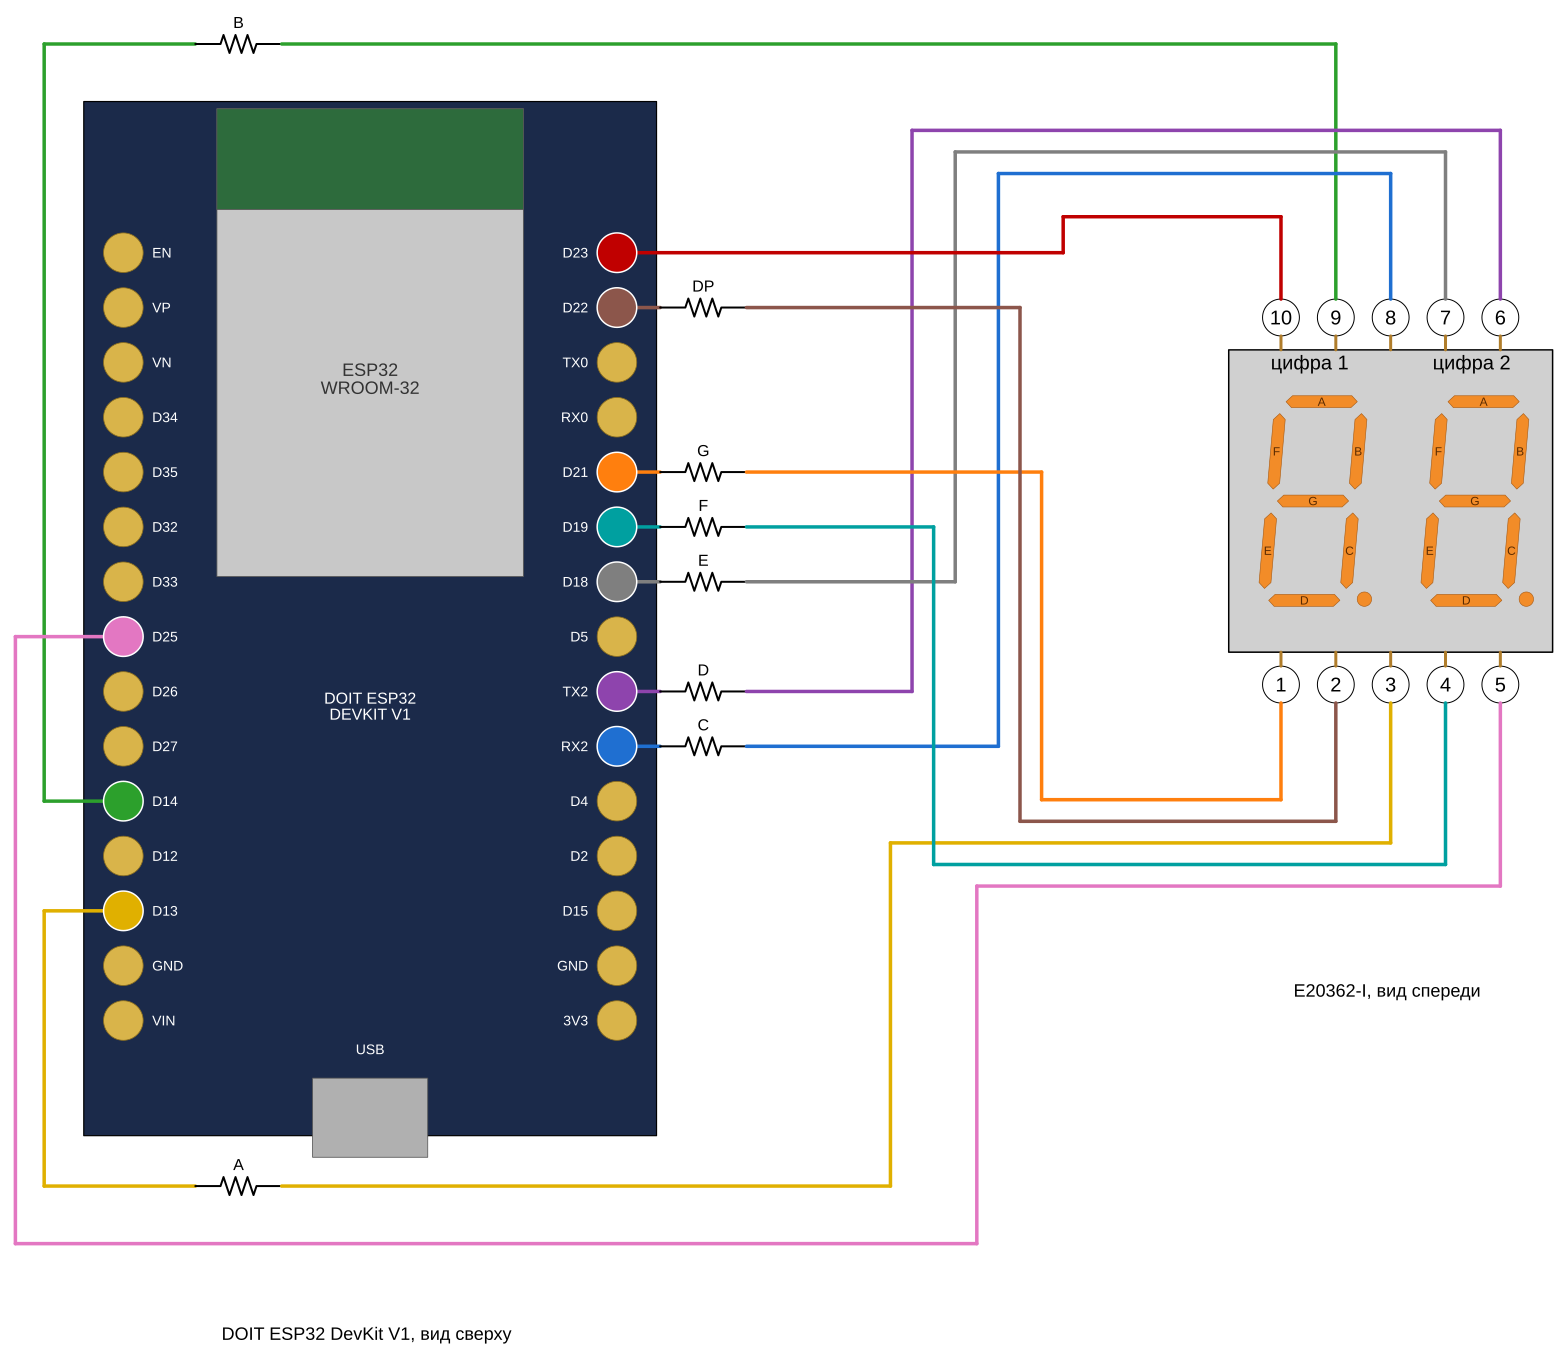

In [4]:
# Монтажная схема: плата и индикатор как они выглядят сверху/спереди, выводы на своих местах.
# Масштаб общий с видом индикатора: K = 0.6 единицы на мм, шаг выводов 2,54 мм.
import itertools

P = 2.54 * K
FS = 2.0                                  # масштаб текста: схема крупная, в документе ужимается
PIN_R = 0.32 * max(1.0, 0.8 * FS)         # радиус кружка вывода индикатора (как в E20362Front)

# DOIT ESP32 DevKit V1 (30 выводов), вид сверху: антенна вверху, USB внизу. Сверху вниз.
DEVKIT_LEFT = ['EN', 'VP', 'VN', 'D34', 'D35', 'D32', 'D33', 'D25', 'D26', 'D27',
               'D14', 'D12', 'D13', 'GND', 'VIN']
DEVKIT_RIGHT = ['D23', 'D22', 'TX0', 'RX0', 'D21', 'D19', 'D18', 'D5', 'TX2', 'RX2',
                'D4', 'D2', 'D15', 'GND', '3V3']
ROW_GAP = 22.86 * K                      # расстояние между рядами выводов платы (0,9″)

# Подключение этапа 1: надпись на плате -> (сигнал, вывод индикатора, резистор?, цвет провода)
WIRES = {
    'D13': ('A', 3, True, '#e0b000'),
    'D14': ('B', 9, True, '#2ca02c'),
    'RX2': ('C', 8, True, '#1f6fd1'),
    'TX2': ('D', 6, True, '#8e44ad'),
    'D18': ('E', 7, True, '#7f7f7f'),
    'D19': ('F', 4, True, '#00a0a0'),
    'D21': ('G', 1, True, '#ff7f0e'),
    'D22': ('DP', 2, True, '#8c564b'),
    'D23': ('DIG1 +', 10, False, PLUS),
    'D25': ('DIG2 +', 5, False, '#e377c2'),
}


class DevKitV1(elm.Element):
    """Плата DOIT ESP32 DevKit V1, вид сверху. Якоря 'L_<надпись>' / 'R_<надпись>' — центры выводов."""
    def __init__(self, used=(), colors=None, **kwargs):
        super().__init__(**kwargs)
        colors = colors or {}
        s = self.segments
        n = len(DEVKIT_LEFT)
        bottom = -(n - 1) * P
        x0, x1 = -1.1, ROW_GAP + 1.1
        y_top, y_bot = 4.2, bottom - 3.2
        s.append(SegmentPoly([(x0, y_bot), (x1, y_bot), (x1, y_top), (x0, y_top)],
                             fill='#1b2a4a', color='black', lw=1.2))                    # плата
        mx0, mx1 = 2.6, ROW_GAP - 2.6
        s.append(SegmentPoly([(mx0, 4.0), (mx1, 4.0), (mx1, -9.0), (mx0, -9.0)],
                             fill='#c8c8c8', color='#555555', lw=0.8))                  # модуль WROOM-32
        s.append(SegmentPoly([(mx0, 4.0), (mx1, 4.0), (mx1, 1.2), (mx0, 1.2)],
                             fill='#2d6b3c', color='#555555', lw=0.8))                  # антенна
        s.append(SegmentText(((mx0 + mx1) / 2, -3.5), 'ESP32\nWROOM-32', fontsize=9 * FS,
                             color='#333333', align=('center', 'center')))
        ux = ROW_GAP / 2
        s.append(SegmentPoly([(ux - 1.6, y_bot - 0.6), (ux + 1.6, y_bot - 0.6),
                              (ux + 1.6, y_bot + 1.6), (ux - 1.6, y_bot + 1.6)],
                             fill='#b0b0b0', color='#555555', lw=0.8))                  # USB
        s.append(SegmentText((ux, y_bot + 2.4), 'USB', fontsize=7 * FS, color='white',
                             align=('center', 'center')))
        s.append(SegmentText((ux, -12.6), 'DOIT ESP32\nDEVKIT V1', fontsize=8 * FS, color='white',
                             align=('center', 'center')))
        for side, names, x, lx, ha in (('L', DEVKIT_LEFT, 0.0, 0.8, 'left'),
                                       ('R', DEVKIT_RIGHT, ROW_GAP, ROW_GAP - 0.8, 'right')):
            for i, name in enumerate(names):
                y = -i * P
                on = name in used
                s.append(SegmentCircle((x, y), 0.55, fill=colors.get(name, '#d9b44a') if on else '#d9b44a',
                                       color='white' if on else '#8a6d1e', lw=1.5 if on else 0.8, zorder=4))
                s.append(SegmentText((lx, y), name, fontsize=7 * FS, color='white',
                                     align=(ha, 'center'), zorder=4))
                self.anchors[f'{side}_{name}'] = (x, y)


# ---------------------------------------------------------------- геометрия
N_ROWS = len(DEVKIT_LEFT)
BOARD_TOP, BOARD_BOT = 4.2, -(N_ROWS - 1) * P - 3.2
src = {n: ((0.0, -DEVKIT_LEFT.index(n) * P) if n in DEVKIT_LEFT
           else (ROW_GAP, -DEVKIT_RIGHT.index(n) * P)) for n in WIRES}

disp_x0 = ROW_GAP + 17.0                       # левый край корпуса индикатора
disp_y0 = -6.9 - H / 2                         # низ корпуса: центр — по задействованным выводам
pin_xy = {}
for i in range(5):
    x = disp_x0 + W / 2 + (i - 2) * P
    pin_xy[i + 1] = (x, disp_y0 - 0.9 - PIN_R)         # нижний ряд: 1..5
    pin_xy[10 - i] = (x, disp_y0 + H + 0.9 + PIN_R)    # верхний ряд: 10..6
TOP, BOT = [10, 9, 8, 7, 6], [1, 2, 3, 4, 5]

# Дорожки: верхние — выше D23 и выше платы не нужно; нижние — ниже RX2. Левее вывод — ближе дорожка.
LANE = 0.6
lane_y = {p: 1.0 + k * LANE for k, p in enumerate(TOP)}
lane_y.update({p: -15.2 - k * LANE for k, p in enumerate(BOT)})

R_LEN = 2.4                                    # длина резистора
CH0, CH = ROW_GAP + 7.6, 0.6                   # первый вертикальный канал и шаг каналов


def route(name, chan):
    """Ломаная провода и место резистора: (точки, (начало резистора, направление)) ."""
    sig, pin, via_r, _ = WIRES[name]
    (sx, sy), (px, py) = src[name], pin_xy[pin]
    ly = lane_y[pin]
    if name in DEVKIT_RIGHT:
        cx = chan[name]
        pts = [(sx, sy), (cx, sy), (cx, ly), (px, ly), (px, py)]
        res = (sx + 1.2, sy) if via_r else None
    elif pin in TOP:                                # левый ряд -> верхний ряд: поверху платы
        k = 0
        ox = -2.2 - k * 0.7
        ty = BOARD_TOP + 1.0 + (lane_y[pin] - 1.0)
        pts = [(sx, sy), (ox, sy), (ox, ty), (px, ty), (px, py)]
        res = (2.0, ty) if via_r else None
    else:                                           # левый ряд -> нижний ряд: понизу платы
        k = ['D13', 'D25'].index(name)
        ox = -2.2 - k * 0.8
        by = BOARD_BOT - 1.4 - k * 1.6
        cx = chan[name]
        pts = [(sx, sy), (ox, sy), (ox, by), (cx, by), (cx, ly), (px, ly), (px, py)]
        res = (2.0, by) if via_r else None
    return pts, res


def crossings(paths):
    segs = []
    for wi, pts in enumerate(paths):
        for a, b in zip(pts, pts[1:]):
            segs.append((wi, a, b))
    n = 0
    for (i, a, b), (j, c, e) in itertools.combinations(segs, 2):
        if i == j:
            continue
        for (h0, h1), (v0, v1) in (((a, b), (c, e)), ((c, e), (a, b))):
            if h0[1] == h1[1] and v0[0] == v1[0]:          # горизонталь × вертикаль
                y, x = h0[1], v0[0]
                if (min(h0[0], h1[0]) < x < max(h0[0], h1[0])
                        and min(v0[1], v1[1]) < y < max(v0[1], v1[1])):
                    n += 1
    return n


# Порядок вертикальных каналов: перебор перестановок с локальным улучшением (меньше пересечений)
chan_wires = [n for n in WIRES if n in DEVKIT_RIGHT or WIRES[n][1] in BOT]
order = sorted(chan_wires, key=lambda n: -abs(lane_y[WIRES[n][1]] + 7))
def cost(order):
    chan = {n: CH0 + k * CH for k, n in enumerate(order)}
    return crossings([route(n, chan)[0] for n in WIRES])
best = cost(order)
improved = True
while improved:
    improved = False
    for i, j in itertools.combinations(range(len(order)), 2):
        cand = order[:]
        cand[i], cand[j] = cand[j], cand[i]
        c = cost(cand)
        if c < best:
            order, best, improved = cand, c, True
chan = {n: CH0 + k * CH for k, n in enumerate(order)}
print('пересечений проводов:', best)

# ---------------------------------------------------------------- рисунок
ROUTE_W = 3.5
with schemdraw.Drawing(show=False) as d:
    d.config(unit=R_LEN)
    d += DevKitV1(used=list(WIRES), colors={k: v[3] for k, v in WIRES.items()}).at((0, 0))
    d += E20362Front(show_func=False, fs=FS).at((disp_x0, disp_y0))

    for name, (sig, pin, via_r, color) in WIRES.items():
        pts, res = route(name, chan)
        if res:  # разрезать ломаную в месте резистора
            (rx, ry) = res
            for a, b in zip(pts, pts[1:]):
                if a[1] == b[1] == ry and min(a[0], b[0]) <= rx < max(a[0], b[0]):
                    seg_end = (rx + R_LEN, ry)
                    d.add(elm.Line(color=color, lw=ROUTE_W).at(a).to((rx, ry)))
                    d.add(elm.Resistor().at((rx, ry)).right().label(sig, loc='top', fontsize=8 * FS))
                    d.add(elm.Line(color=color, lw=ROUTE_W).at(seg_end).to(b))
                else:
                    d.add(elm.Line(color=color, lw=ROUTE_W).at(a).to(b))
        else:
            for a, b in zip(pts, pts[1:]):
                d.add(elm.Line(color=color, lw=ROUTE_W).at(a).to(b))

    d += elm.Label().at((disp_x0 + W / 2, disp_y0 - 9.5)).label('E20362-I, вид спереди', fontsize=9 * FS)
    d += elm.Label().at((ROW_GAP / 2, BOARD_BOT - 5.6)).label('DOIT ESP32 DevKit V1, вид сверху', fontsize=9 * FS)
save(d, 'layout')


## Подключение к ESP32 — принципиальная схема (этап 1)

То же подключение в принципиальном виде: каждая линия — пин ESP32 → резистор → вывод индикатора, аноды цифр — напрямую. У пинов — номер GPIO и надпись на плате DOIT DevKit V1, у индикатора — номер вывода и сигнал.

Должно совпадать с таблицей в [03-hardware.md](../03-hardware.md) и пинами по умолчанию в `led_clock.ino`.

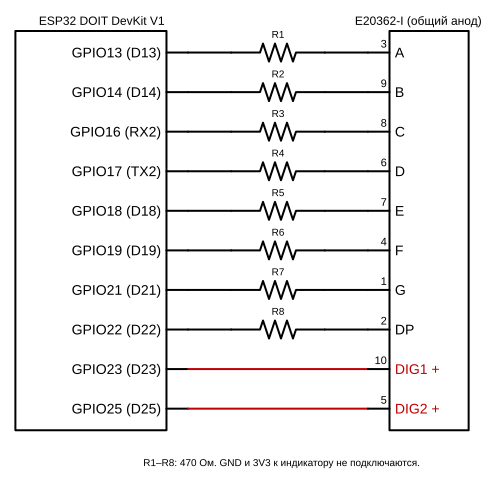

In [5]:
# Принципиальная схема подключения: ESP32 -> R1..R8 -> E20362, аноды напрямую.
# Данные — как в 03-hardware.md и config.example.h.
LINES = [  # (надпись на плате, GPIO, сигнал, вывод индикатора, через резистор)
    ('D13', 13, 'A', 3, True),
    ('D14', 14, 'B', 9, True),
    ('RX2', 16, 'C', 8, True),
    ('TX2', 17, 'D', 6, True),
    ('D18', 18, 'E', 7, True),
    ('D19', 19, 'F', 4, True),
    ('D21', 21, 'G', 1, True),
    ('D22', 22, 'DP', 2, True),
    ('D23', 23, 'DIG1 +', 10, False),
    ('D25', 25, 'DIG2 +', 5, False),
]
PITCH = 1.1                                   # шаг между линиями
BOX_H = (len(LINES) - 1) * PITCH + 1.2        # высота корпусов под 10 выводов
# Выводы elm.Ic перечисляются снизу вверх — список разворачиваем, чтобы A была сверху.
ORDER = list(reversed(list(enumerate(LINES))))

with schemdraw.Drawing(show=False) as d:
    d.config(unit=2.5)
    esp = elm.Ic(size=(4.2, BOX_H), pinspacing=PITCH, edgepadH=0.6, leadlen=0.6,
                 pins=[elm.IcPin(name=f'GPIO{gpio} ({lbl})', side='right', anchorname=f'p{i}')
                       for i, (lbl, gpio, *_) in ORDER]
                 ).label('ESP32 DOIT DevKit V1', loc='top', fontsize=12)
    d += esp

    r_idx, end_x = 0, None
    for i, (lbl, gpio, sig, pin, via_r) in enumerate(LINES):
        start = getattr(esp, f'p{i}')
        if via_r:
            r_idx += 1
            d += elm.Line().at(start).right(1.2)
            d += elm.Resistor().right(2.6).label(f'R{r_idx}', loc='top', fontsize=10)
            d += elm.Line().right(1.2)
        else:
            d += elm.Line(color=PLUS).at(start).right(5.0)
        end_x = d.here.x

    disp = elm.Ic(size=(2.2, BOX_H), pinspacing=PITCH, edgepadH=0.6, leadlen=0.6,
                  pins=[elm.IcPin(name=sig, pin=str(pin), side='left', anchorname=f'q{i}',
                                  color=PLUS if '+' in sig else None)
                        for i, (_, _, sig, pin, _) in ORDER]
                  ).label('E20362-I (общий анод)', loc='top', fontsize=12)
    d += disp.anchor('q0').at((end_x, esp.p0.y))   # вывод A индикатора — на конец линии A

    bottom = min(getattr(esp, f'p{i}').y for i in range(len(LINES))) - 1.6
    d += elm.Label().at(((esp.p0.x + end_x) / 2, bottom)).label(
        'R1–R8: 470 Ом.   GND и 3V3 к индикатору не подключаются.', fontsize=10)
save(d, 'connection')


## Подключение к ESP32 — схема проводов WireViz (для сравнения)

То же подключение в виде схемы жгутов: `W1`, `W2`, `W3` — группы проводов (W1: ESP32 → резисторы, W2: резисторы → индикатор, W3: аноды), цвета — рекомендация для макетки. Основная схема — принципиальная выше.

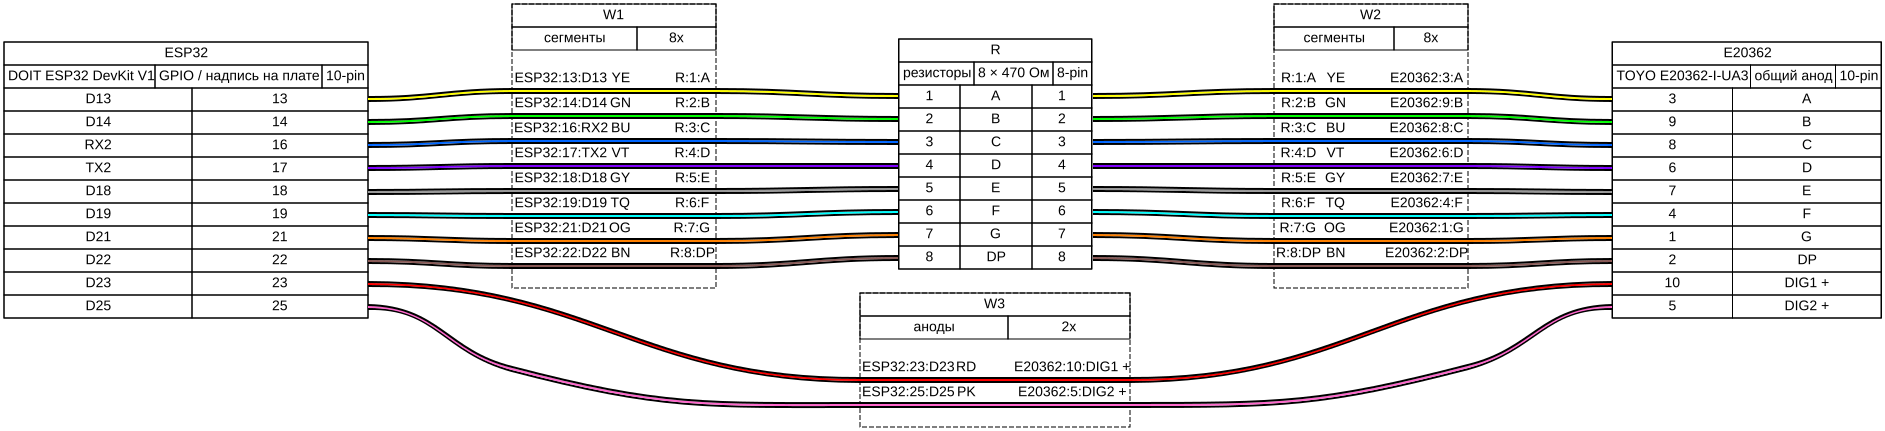

In [6]:
from wireviz.wireviz import parse

WIRING = '''
options:
  fontname: arial
  bgcolor: WH
  bgcolor_node: WH
  bgcolor_connector: WH
  bgcolor_cable: WH
  bgcolor_bundle: WH

connectors:
  ESP32:
    type: DOIT ESP32 DevKit V1
    subtype: GPIO / надпись на плате
    pins:      [13,  14,  16,  17,  18,  19,  21,  22,  23,  25]
    pinlabels: [D13, D14, RX2, TX2, D18, D19, D21, D22, D23, D25]
  R:
    type: резисторы
    subtype: 8 × 470 Ом
    pins:      [1, 2, 3, 4, 5, 6, 7, 8]
    pinlabels: [A, B, C, D, E, F, G, DP]
  E20362:
    type: TOYO E20362-I-UA3
    subtype: общий анод
    pins:      [3, 9, 8, 6, 7, 4, 1, 2, 10, 5]
    pinlabels: [A, B, C, D, E, F, G, DP, DIG1 +, DIG2 +]

cables:
  W1: {category: bundle, type: сегменты, colors: [YE, GN, BU, VT, GY, TQ, OG, BN], show_wirenumbers: false}
  W2: {category: bundle, type: сегменты, colors: [YE, GN, BU, VT, GY, TQ, OG, BN], show_wirenumbers: false}
  W3: {category: bundle, type: аноды,    colors: [RD, PK],                         show_wirenumbers: false}

connections:
  - [ESP32: [13, 14, 16, 17, 18, 19, 21, 22], W1: [1-8], R: [1-8]]
  - [R: [1-8], W2: [1-8], E20362: [3, 9, 8, 6, 7, 4, 1, 2]]
  - [ESP32: [23, 25], W3: [1-2], E20362: [10, 5]]
'''

parse(WIRING, output_formats=('svg',), output_dir=str(OUT), output_name='wiring')
display(SVG(filename=str(OUT / 'wiring.svg')))